# code_183 · A search space is part of the model specification

**Book:** section 35.1. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_35_GUIDE.md), [execution evidence](../CHAPTER_35_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_183).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Configuration spaces, data roles, selection information and resource accounting are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7683;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7683


<a id="declare-conditional-spaces"></a>
 ## Draw valid configurations before looking at any development result
 Generate 180 independent buildings with four repeated operating records each. Each building contributes shared features and an unobserved disturbance. Fit/source 108 buildings, development 36 and final 36 are disjoint. Three features are visible at building level; load and two row-level sensor features vary by record. Missingness affects five percent of feature values independently. The task is continuous maintenance burden under a fixed generated law. Group identity is a role key, never a model input.

 Declare twelve candidates, six histogram boosting and six original two-layer neural regressors. Boosting learns sixty trees with no automatic early stopping; conditional hyperparameters are depth 2/3/5, minimum leaf 8/16 and learning rate log-uniform 0.01–0.2. Neural candidates fit 150 full-batch Adam updates; conditional hyperparameters are width 8/24, learning rate log-uniform 0.001–0.03, weight decay log-uniform 10^-5–10^-2 and StandardScaler/RobustScaler. Neural imputation and scaling fit only source records. Boosting retains missing values natively. Different tree and neural allocations are stated, not advertised as equal compute. All configurations are drawn before any development score. The final outcomes remain untouched until one configuration is selected.


    family  depth  min_leaf  learning_rate  trees missingness  width  \
0    Boost    5.0       8.0       0.075159   60.0      native    NaN   
1    Boost    2.0       8.0       0.125278   60.0      native    NaN   
2    Boost    3.0       8.0       0.149560   60.0      native    NaN   
3    Boost    5.0      16.0       0.064097   60.0      native    NaN   
4    Boost    2.0       8.0       0.083347   60.0      native    NaN   
5    Boost    3.0       8.0       0.088774   60.0      native    NaN   
6   Neural    NaN       NaN       0.015361    NaN         NaN    8.0   
7   Neural    NaN       NaN       0.004137    NaN         NaN    8.0   
8   Neural    NaN       NaN       0.023234    NaN         NaN   24.0   
9   Neural    NaN       NaN       0.027492    NaN         NaN    8.0   
10  Neural    NaN       NaN       0.029866    NaN         NaN    8.0   
11  Neural    NaN       NaN       0.015438    NaN         NaN    8.0   

    weight_decay   scaling  updates  
0            NaN       Na

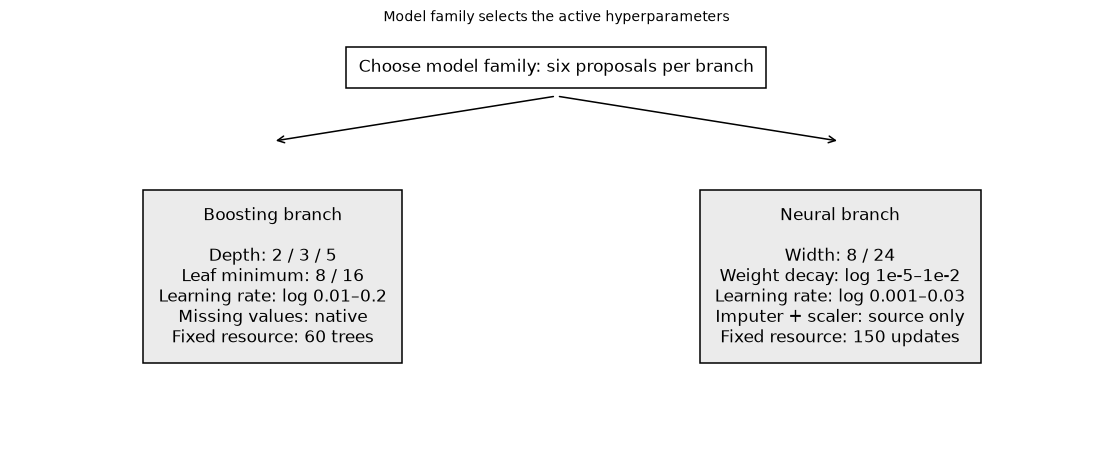

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,RobustScaler
from sklearn.metrics import mean_squared_error
buildings=180;rows=4;group=np.repeat(np.arange(buildings),rows);bf=rng.normal(size=(buildings,3));frailty=rng.normal(scale=.6,size=buildings);load=rng.uniform(-1,1,(buildings*rows,1));sensors=rng.normal(size=(buildings*rows,2));X=np.c_[bf[group],load,sensors];Y=1.2*X[:,0]+.8*np.sin(2*X[:,1])+.7*X[:,2]*X[:,3]+.4*X[:,4]+frailty[group]+rng.normal(scale=.25,size=buildings*rows);X[rng.random(X.shape)<.05]=np.nan;order=rng.permutation(buildings);SG=order[:108];DG=order[108:144];FG=order[144:];source=np.isin(group,SG);development=np.isin(group,DG);final=np.isin(group,FG);assert not(set(SG)&set(DG) or set(SG)&set(FG) or set(DG)&set(FG))
gr=np.random.default_rng(SEED+10);configs=[]
for family in ['Boost','Neural']:
    for trial in range(6):
        c={'family':family}
        if family=='Boost':c.update(depth=int(gr.choice([2,3,5])),min_leaf=int(gr.choice([8,16])),learning_rate=float(np.exp(gr.uniform(np.log(.01),np.log(.2)))),trees=60,missingness='native')
        else:c.update(width=int(gr.choice([8,24])),learning_rate=float(np.exp(gr.uniform(np.log(.001),np.log(.03)))),weight_decay=float(np.exp(gr.uniform(np.log(1e-5),np.log(1e-2)))),scaling=str(gr.choice(['standard','robust'])),updates=150)
        configs.append(c)
assert all(('depth' in c)==(c['family']=='Boost') and ('width' in c)==(c['family']=='Neural') for c in configs)
print(pd.DataFrame(configs));RESULTS.update(source_buildings=108,development_buildings=36,final_buildings=36,records_per_building=4,configs_drawn_before_scores=configs,group_identity_used_as_feature=False)
fig,ax=plt.subplots(figsize=(10,4));ax.axis('off');ax.set(xlim=(0,1),ylim=(0,1));ax.text(.5,.91,'Choose model family: six proposals per branch',ha='center',va='center',fontsize=11,bbox={'facecolor':'white','edgecolor':'black','pad':8})
ax.text(.24,.40,'Boosting branch\n\nDepth: 2 / 3 / 5\nLeaf minimum: 8 / 16\nLearning rate: log 0.01–0.2\nMissing values: native\nFixed resource: 60 trees',ha='center',va='center',fontsize=11,bbox={'facecolor':'.92','edgecolor':'black','pad':10})
ax.text(.76,.40,'Neural branch\n\nWidth: 8 / 24\nWeight decay: log 1e-5–1e-2\nLearning rate: log 0.001–0.03\nImputer + scaler: source only\nFixed resource: 150 updates',ha='center',va='center',fontsize=11,bbox={'facecolor':'.92','edgecolor':'black','pad':10})
for xx in [.24,.76]:ax.annotate('',xy=(xx,.73),xytext=(.5,.84),arrowprops={'arrowstyle':'->','color':'black'})
ax.set_title('Model family selects the active hyperparameters');plt.show()


<a id="fitted-transformations-and-final-selection"></a>
 ## Fit model parameters inside the declared source boundary
 Hyperparameters specify a fitting procedure; tree splits, leaf values and neural weights are learned by that procedure. A scaler's centre and an imputer's medians are learned parameters too, despite being outside the response estimator. Retain source-only statistics and check them against independent calculations. Each candidate scores development records once. Select minimum development RMSE with deterministic first-trial tie breaking. Refit that exact configuration from its original seed on source records, then assess it once on the final 36 buildings. Keeping development separate means it is not silently added during this refit. Later sections will examine other explicit refitting policies.

 Source and development RMSE differences diagnose fitting, not an estimate of search generalization by themselves. Final truth is used only for the selected candidate. Family allocations are different resources; this laboratory does not claim a fair equal-time architecture benchmark. Every plotted point is an actual fitted candidate, not an invented response surface.


,trial,family,source_RMSE,development_RMSE
0,0,Boost,0.400985,0.824659
1,1,Boost,0.688673,0.819736
2,2,Boost,0.466091,0.776016
3,3,Boost,0.529142,0.792430
4,4,Boost,0.748085,0.803709
5,5,Boost,0.577932,0.787761
6,6,Neural,0.761962,0.768069
7,7,Neural,0.922946,0.842137
8,8,Neural,0.646475,0.848034
9,9,Neural,0.725977,0.773197


Selected trial: 11 final RMSE: 0.916686586568217


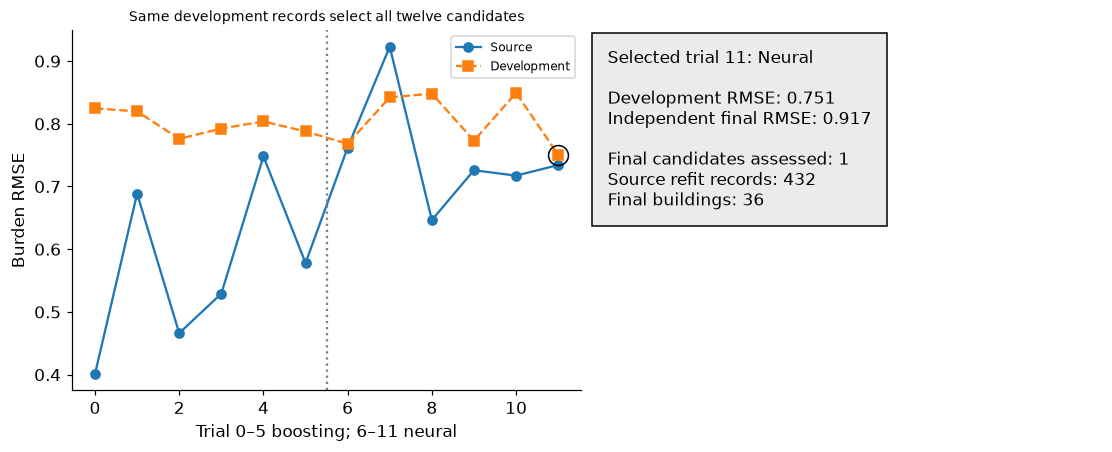

In [3]:
def fit_config(c,seed):
    if c['family']=='Boost':
        model=HistGradientBoostingRegressor(max_iter=c['trees'],max_depth=c['depth'],min_samples_leaf=c['min_leaf'],learning_rate=c['learning_rate'],early_stopping=False,random_state=seed).fit(X[source],Y[source]);return model.predict,{'fitted_trees':int(model.n_iter_),'source_fitted_rows':int(source.sum()),'transform':'native missing-value routing'}
    imputer=SimpleImputer(strategy='median');z=imputer.fit_transform(X[source]);scaler=(StandardScaler() if c['scaling']=='standard' else RobustScaler()).fit(z);z=scaler.transform(z);torch.manual_seed(seed);net=nn.Sequential(nn.Linear(6,c['width']),nn.Tanh(),nn.Linear(c['width'],1));optimizer=torch.optim.Adam(net.parameters(),lr=c['learning_rate'],weight_decay=c['weight_decay'])
    for step in range(c['updates']):
        loss=nn.functional.mse_loss(net(torch.tensor(z)).squeeze(1),torch.tensor(Y[source]));optimizer.zero_grad();loss.backward();optimizer.step()
    np.testing.assert_allclose(imputer.statistics_,np.nanmedian(X[source],axis=0))
    expected_centre=np.mean(imputer.transform(X[source]),axis=0) if c['scaling']=='standard' else np.median(imputer.transform(X[source]),axis=0);actual=scaler.mean_ if c['scaling']=='standard' else scaler.center_;np.testing.assert_allclose(actual,expected_centre)
    def predict(x):
        with torch.no_grad():return net(torch.tensor(scaler.transform(imputer.transform(x)))).squeeze(1).numpy()
    return predict,{'learned_neural_weights':sum(p.numel() for p in net.parameters()),'imputer_medians':imputer.statistics_.tolist(),'scaler_centre':actual.tolist(),'source_fitted_rows':int(source.sum()),'updates':c['updates']}
trials=[]
for j,c in enumerate(configs):
    predict,details=fit_config(c,SEED+j);trials.append({'trial':j,'family':c['family'],'source_RMSE':float(np.sqrt(mean_squared_error(Y[source],predict(X[source])))),'development_RMSE':float(np.sqrt(mean_squared_error(Y[development],predict(X[development])))),'fitted_parameters':details})
selected=min(range(len(trials)),key=lambda j:trials[j]['development_RMSE']);predict,details=fit_config(configs[selected],SEED+selected);final_rmse=float(np.sqrt(mean_squared_error(Y[final],predict(X[final]))));assert len(trials)==12 and np.isfinite(final_rmse) and details['source_fitted_rows']==432
RESULTS.update(candidate_results=trials,selected_trial=selected,selected_configuration=configs[selected],selected_final_RMSE=final_rmse,final_building_IDs=FG.tolist(),final_assessed_candidate_count=1,selection_rule='lowest development RMSE; first trial on ties',refit_data='same source only, same seed and fixed resource',development_added_to_refit=False)
display(pd.DataFrame([{k:v for k,v in r.items() if k!='fitted_parameters'} for r in trials]));print('Selected trial:',selected,'final RMSE:',final_rmse);fig,axes=plt.subplots(1,2,figsize=(10,4));ids=np.arange(12);axes[0].plot(ids,[r['source_RMSE'] for r in trials],'o-',label='Source');axes[0].plot(ids,[r['development_RMSE'] for r in trials],'s--',label='Development');axes[0].axvline(5.5,color='.5',linestyle=':');axes[0].plot(selected,trials[selected]['development_RMSE'],'o',markersize=13,fillstyle='none',color='black');axes[0].set(xlabel='Trial 0–5 boosting; 6–11 neural',ylabel='Burden RMSE',title='Same development records select all twelve candidates');axes[0].legend(fontsize=8);axes[1].axis('off');axes[1].text(.03,.95,f'Selected trial {selected}: {configs[selected]["family"]}\n\nDevelopment RMSE: {trials[selected]["development_RMSE"]:.3f}\nIndependent final RMSE: {final_rmse:.3f}\n\nFinal candidates assessed: 1\nSource refit records: 432\nFinal buildings: 36',va='top',fontsize=11,bbox={'facecolor':'.92','edgecolor':'black','pad':10});plt.show()


In [4]:
summary={'example_id':'code_183','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual conditional boosting and neural search configurations', 'family-specific logarithmic learning-rate and regularization ranges', 'source-only missing-value and scaling fits', 'development-only model selection with one final locked assessment', 'explicit different tree and neural update allocations'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual conditional boosting and neural search configurations", "family-specific logarithmic learning-rate and regularization ranges", "source-only missing-value and scaling fits", "development-only model selection with one final locked assessment", "explicit different tree and neural update allocations"], "elapsed_seconds": 0.997, "example_id": "code_183", "hardware": "Darwin arm64 CPU", "results": {"candidate_results": [{"development_RMSE": 0.8246588849775117, "family": "Boost", "fitted_parameters": {"fitted_trees": 60, "source_fitted_rows": 432, "transform": "native missing-value routing"}, "source_RMSE": 0.4009852502863363, "trial": 0}, {"development_RMSE": 0.8197356918286526, "family": "Boost", "fitted_parameters": {"fitted_trees": 60, "source_fitted_rows": 432, "transform": "native missing-value routing"}, "source_RMSE": 0.6886729268626555, "trial": 1}, {"development_RMSE": 0.7760164723714518, "family": "Boost", "fitted_parameters